# IND320 — Project Work, Part 3

**GitHub repository:** https://github.com/isach07/IND320_isachstevik

**Streamlit app:** https://ind320isachstevik-dsj69wxyp9oamezekyfwal.streamlit.app

**Video presentation:** 

In [1]:
import requests
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

## Sampling 1000 random locations

The goal is 1000 random locations in Norway, each labelled with the electricity price area and the precipitation area it belongs to, using the same areas as the Magasinstatistikk data (`EL` and `VASS`).

The price areas match directly: `NO 1` in the shapefile is `EL 1` in Magasinstatistikk. The NVE regions have to be combined, because Magasinstatistikk only has three precipitation areas with data, while the shapefile has five regions:

| Magasinstatistikk | Area | NVE regions |
|---|---|---|
| `VASS 1` | East | RS + RØ |
| `VASS 2` | West | RV |
| `VASS 3` | North | RM + RN |


In [2]:
import geopandas as gpd

# Both shapefiles are in EPSG:25833 (metres). The encoding is set so RØ is read correctly.
price_areas = gpd.read_file("../Data/Budområder/Budområder.shp")[["budomr", "geometry"]]
nve_regions = gpd.read_file("../Data/NVE_Region/NVE_Region.shp", encoding="utf-8")[["REGION", "REGIONNAVN", "geometry"]]

# same labels as the area column in the Magasinstatistikk data from part 2
price_areas["el_area"] = price_areas["budomr"].str.replace("NO", "EL")

REGION_TO_VASS = {"RS": "VASS 1", "RØ": "VASS 1", "RV": "VASS 2", "RM": "VASS 3", "RN": "VASS 3"}
nve_regions["vass_area"] = nve_regions["REGION"].map(REGION_TO_VASS)
nve_regions.drop(columns="geometry")


,REGION,REGIONNAVN,vass_area
0,RV,Region Vest,VASS 2
1,RM,Region Midt-Norge,VASS 3
2,RN,Region Nord,VASS 3
3,RØ,Region Øst,VASS 1
4,RS,Region Sør,VASS 1


NVE describes `VASS 3` as Midt-Norge and lists a separate `VASS 4` for the north, but `VASS 4` has no data. The check below shows that `VASS 1`–`VASS 3` add up to the capacity of the whole country, so `VASS 3` must include the north. That is why RM and RN belong together.


In [3]:
NVE_BASE = "https://biapi.nve.no/magasinstatistikk/api/Magasinstatistikk"

reservoirs = pd.DataFrame(requests.get(f"{NVE_BASE}/HentOffentligData", timeout=60).json())
latest = reservoirs[reservoirs["dato_Id"] == reservoirs["dato_Id"].max()]

# reservoir capacity for each VASS area, compared with the total for Norway (NO)
capacity = latest[latest["omrType"].isin(["NO", "VASS"])].set_index(["omrType", "omrnr"])["kapasitet_TWh"].sort_index()
print(capacity.round(2))
print(f"Sum of VASS: {capacity['VASS'].sum():.2f} TWh")


omrType  omrnr
NO       0        87.44
VASS     1        36.04
         2        23.24
         3        28.16
Name: kapasitet_TWh, dtype: float64
Sum of VASS: 87.44 TWh


In [4]:
SEED = 320   # fixed so the same 1000 locations come back on every run
N_POINTS = 1000

# The outlines of the two shapefiles differ slightly, so only keep the area covered by both.
# This also gives one piece per combination of price area and region.
both = gpd.overlay(price_areas, nve_regions, how="intersection", keep_geom_type=True)

# Uniform over the area, so a larger area gets more locations
norway = gpd.GeoSeries([both.union_all()], crs=both.crs)
points = norway.sample_points(N_POINTS, rng=SEED).explode(ignore_index=True)

# look up which piece each location falls in
samples = gpd.sjoin(gpd.GeoDataFrame(geometry=points), both, predicate="within", how="left")

# longitude and latitude, for looking the locations up in other data sources
lonlat = samples.geometry.to_crs(epsg=4326)
samples["lon"] = lonlat.x
samples["lat"] = lonlat.y

samples = samples[["lon", "lat", "el_area", "REGION", "vass_area", "geometry"]]
samples.head()


,lon,lat,el_area,REGION,vass_area,geometry
0,7.448009,58.865260,EL 2,RS,VASS 1,POINT (65015.967 6549641.148)
1,10.980912,61.613299,EL 1,RØ,VASS 1,POINT (286923.665 6837681.112)
2,10.600920,62.155378,EL 1,RØ,VASS 1,POINT (270889.457 6899272.118)
3,10.969834,59.002215,EL 1,RØ,VASS 1,POINT (268562.202 6547280.301)
4,7.321573,59.013810,EL 2,RS,VASS 1,POINT (59656.024 6566943.217)


In [5]:
# every location should have exactly one price area and one precipitation area
assert len(samples) == N_POINTS
assert samples[["el_area", "vass_area"]].notna().all().all()

# number of locations per combination of areas
pd.crosstab(samples["el_area"], samples["vass_area"], margins=True)


vass_area,VASS 1,VASS 2,VASS 3,All
el_area,,,,
EL 1,126,0,3,129
EL 2,119,19,0,138
EL 3,27,77,93,197
EL 4,0,0,450,450
EL 5,19,67,0,86
All,291,163,546,1000


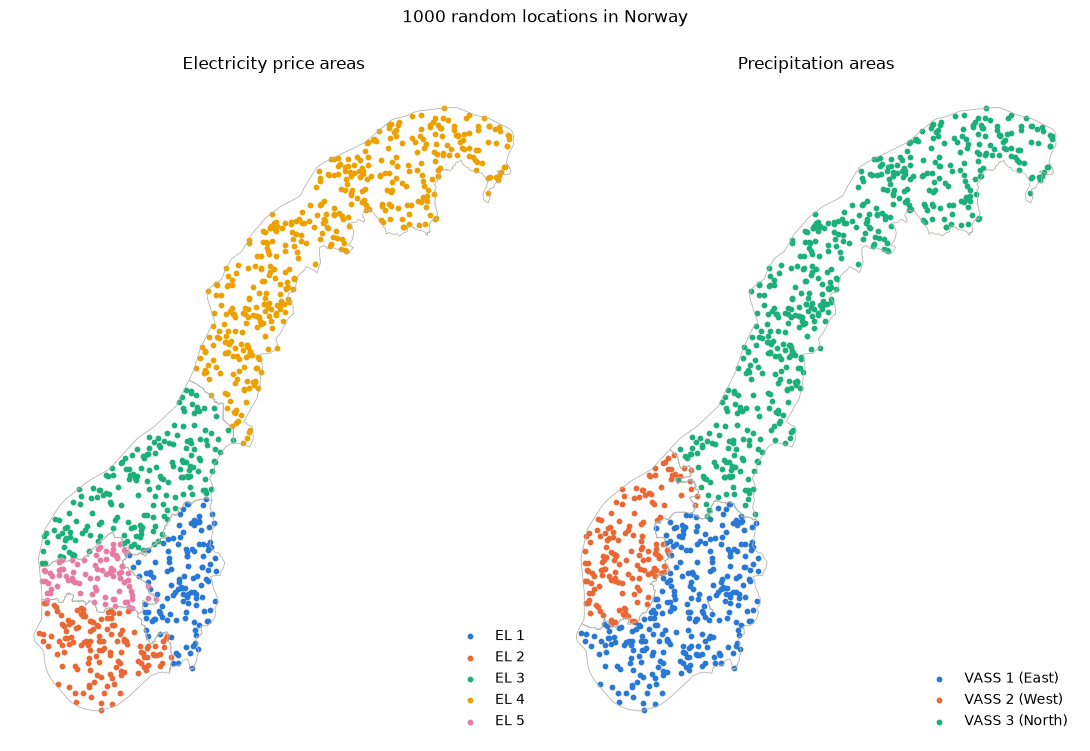

In [6]:
# Map of the sampled locations, once per area type
EL_COLORS = dict(zip(sorted(price_areas["el_area"]), ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]))
VASS_COLORS = dict(zip(sorted(set(REGION_TO_VASS.values())), ["#2a78d6", "#eb6834", "#1baf7a"]))
VASS_LABELS = {"VASS 1": "VASS 1 (East)", "VASS 2": "VASS 2 (West)", "VASS 3": "VASS 3 (North)"}

fig, axes = plt.subplots(1, 2, figsize=(11, 8), sharex=True, sharey=True)

for ax, areas, column, colors, title in [
    (axes[0], price_areas, "el_area", EL_COLORS, "Electricity price areas"),
    (axes[1], nve_regions.dissolve("vass_area").reset_index(), "vass_area", VASS_COLORS, "Precipitation areas"),
]:
    areas.boundary.plot(ax=ax, color="#b5b4ad", linewidth=0.6)
    for area, group in samples.groupby(column):
        group.plot(ax=ax, color=colors[area], markersize=10, label=VASS_LABELS.get(area, area))
    ax.set_title(title)
    ax.set_axis_off()
    ax.legend(loc="lower right", frameon=False)

fig.suptitle(f"{N_POINTS} random locations in Norway")
plt.tight_layout()
plt.show()


In [ ]:
# save the locations for the Streamlit app, which reads them instead of sampling again
samples.drop(columns="geometry").rename_axis("point_id").to_csv("../Data/sample_locations.csv")


## Weather data from Open-Meteo (ERA5)

The weather data comes from Open-Meteo's historical API, using the ERA5 reanalysis model (`models=era5`, about 25 km resolution). `download_weather` takes a region (`EL 1`–`EL 5` or `VASS 1`–`VASS 3`) and a time interval, finds the sampled locations in that region, and downloads daily values for each one.

**API limits:** the free tier allows 10,000 calls per day, 5,000 per hour and 600 per minute, but a request can count as more than one call. The `X-RateLimit-Cost` response header shows the real cost, which I measured:

| Request (one location) | Cost in calls |
|---|---|
| 14 days, 10 variables | 1.00 |
| 1 year, 10 variables | 26.07 |
| 1 year, 5 variables | 13.04 |
| 1 year, 12 variables | 31.29 |

So the cost is about `days / 14 × variables / 10` per location, with a minimum of 1 call. One year for all 1000 locations costs about 26,000 calls, which is more than one day allows. To stay inside the limits the function:

- saves each location and year to `No_sync/era5/`, so nothing is downloaded twice, even though each location belongs to both an `EL` and a `VASS` area
- counts the calls used today and stops at `DAILY_BUDGET`; running it again the next day continues where it stopped
- waits between requests to stay under the hourly limit
- waits and tries again when the API is busy or not answering, and stops if the API answers 429 for the daily limit
- with `dry_run=True`, only prints what a download would cost

ERA5 data arrives about 5 days late, so the end date is moved back if it is too recent. Otherwise, empty days would be saved in the cache.

Locations in the same ERA5 grid cell are still downloaded separately: Open-Meteo adjusts the temperature to each location's own elevation, so the temperature and the split between rain and snow differ even inside one cell.


In [7]:
import hashlib
import json
import time
from datetime import date, datetime, timedelta, timezone
from pathlib import Path

ERA5_URL = "https://archive-api.open-meteo.com/v1/archive"

# Exactly 10 variables: each extra one adds 10% to the cost of every request
DAILY_VARIABLES = [
    "precipitation_sum",           # mm, rain and snow together
    "rain_sum",                    # mm
    "snowfall_sum",                # cm, snow stored until it melts
    "precipitation_hours",         # hours with precipitation
    "temperature_2m_mean",         # °C
    "temperature_2m_max",          # °C
    "temperature_2m_min",          # °C
    "wind_speed_10m_mean",         # m/s
    "shortwave_radiation_sum",     # MJ/m², drives snowmelt
    "et0_fao_evapotranspiration",  # mm, water lost to the air
]

DAILY_BUDGET = 9000     # stay under the limit of 10,000, in case other things use the API
HOURLY_LIMIT = 5000
ERA5_DELAY_DAYS = 7     # 5 days according to the docs, with some margin

CACHE_DIR = Path("../No_sync/era5")   # gitignored
USAGE_FILE = CACHE_DIR / "usage.json"


In [8]:
def calls_used_today():
    """Calls counted so far today. The day follows UTC."""
    today = str(datetime.now(timezone.utc).date())
    if not USAGE_FILE.exists():
        return 0.0
    return json.loads(USAGE_FILE.read_text()).get(today, 0.0)

def add_calls(cost):
    """Add the cost of a request to today's total."""
    today = str(datetime.now(timezone.utc).date())
    usage = json.loads(USAGE_FILE.read_text()) if USAGE_FILE.exists() else {}
    usage[today] = usage.get(today, 0.0) + cost
    USAGE_FILE.write_text(json.dumps(usage))

def locations_in_region(region):
    """Look up the sampled locations for a region, e.g. "EL 1" or "VASS 3"."""
    column = "el_area" if region.startswith("EL") else "vass_area"
    points = samples.loc[samples[column] == region, ["lon", "lat", "el_area", "vass_area"]]
    if points.empty:
        raise ValueError(f"Unknown region: {region}")
    return points

def split_by_year(start, end):
    """Split an interval into one (start, end) pair per calendar year."""
    return [
        (max(start, date(year, 1, 1)), min(end, date(year, 12, 31)))
        for year in range(start.year, end.year + 1)
    ]

def estimate_cost(chunk_start, chunk_end, n_variables):
    """Cost in API calls of one request for one location."""
    days = (chunk_end - chunk_start).days + 1
    return max(days / 14 * n_variables / 10, 1)

def cache_path(lon, lat, chunk_start, chunk_end, variables):
    """File for one location and year. The hash keeps different variable lists apart."""
    variables_id = hashlib.md5(",".join(variables).encode()).hexdigest()[:8]
    return CACHE_DIR / variables_id / f"{lat:.4f}_{lon:.4f}_{chunk_start}_{chunk_end}.parquet"

def fetch_location(lon, lat, chunk_start, chunk_end, variables):
    """Download one location and year. Returns the data and the real cost in calls."""
    resp = requests.get(ERA5_URL, timeout=20, params={   # a normal answer takes under a second
        "latitude": lat,
        "longitude": lon,
        "start_date": chunk_start,
        "end_date": chunk_end,
        "daily": ",".join(variables),
        "models": "era5",
        "timezone": "Europe/Oslo",   # days match the Norwegian calendar, as in part 2
        "wind_speed_unit": "ms",
    })
    resp.raise_for_status()
    result = resp.json()
    data = pd.DataFrame(result["daily"]).rename(columns={"time": "date"})
    data["date"] = pd.to_datetime(data["date"])
    # the ERA5 grid cell that was actually used, which is often not at the exact location
    data["grid_lat"] = result["latitude"]
    data["grid_lon"] = result["longitude"]
    data["elevation"] = result["elevation"]
    return data, float(resp.headers["X-RateLimit-Cost"])


In [9]:
def is_busy(error):
    """Server errors (5xx) and 429 "Too many concurrent requests" mean the server is busy,
    not that our limit is used up."""
    status = error.response.status_code
    return status >= 500 or (status == 429 and "concurrent" in error.response.text)

def fetch_with_retries(lon, lat, chunk_start, chunk_end, variables, attempts=6):
    """Try again when the API is busy or not answering. The wait grows: 30 s, 60 s, ... up to 5 min."""
    for attempt in range(1, attempts + 1):
        try:
            return fetch_location(lon, lat, chunk_start, chunk_end, variables)
        except (requests.Timeout, requests.ConnectionError, requests.HTTPError) as error:
            if isinstance(error, requests.HTTPError) and not is_busy(error):
                raise
            if attempt == attempts:
                raise
            wait = min(30 * 2 ** (attempt - 1), 300)
            print(f"  the API is busy, trying again in {wait} s (attempt {attempt} of {attempts})")
            time.sleep(wait)

def download_weather(region, start, end, variables=DAILY_VARIABLES, dry_run=False):
    """Daily ERA5 weather for all sampled locations in a region.

    region: "EL 1"-"EL 5" or "VASS 1"-"VASS 3"
    start, end: dates as text, e.g. "2024-01-01" (both included)
    dry_run: only print what the download would cost

    Returns what is available so far. If the daily budget runs out, the same
    call continues from where it stopped the next day.
    """
    CACHE_DIR.mkdir(parents=True, exist_ok=True)
    start = date.fromisoformat(start)
    end = date.fromisoformat(end)

    latest = date.today() - timedelta(days=ERA5_DELAY_DAYS)
    if end > latest:
        print(f"ERA5 is not available that late, using {latest} as the end date")
        end = latest

    points = locations_in_region(region)
    chunks = split_by_year(start, end)

    # one job per location and year; the ones already saved are skipped
    jobs = [
        (point_id, point.lon, point.lat, chunk_start, chunk_end)
        for point_id, point in points.iterrows()
        for chunk_start, chunk_end in chunks
    ]
    paths = {job: cache_path(job[1], job[2], job[3], job[4], variables) for job in jobs}
    todo = [job for job in jobs if not paths[job].exists()]

    cost = sum(estimate_cost(job[3], job[4], len(variables)) for job in todo)
    used = calls_used_today()
    print(f"{region}: {len(points)} locations, {len(jobs) - len(todo)} of {len(jobs)} requests already saved")
    print(f"Cost of the rest: {cost:.0f} calls. Used today: {used:.0f} of {DAILY_BUDGET}.")
    if dry_run:
        return None

    done = 0
    for job in todo:
        point_id, lon, lat, chunk_start, chunk_end = job
        estimate = estimate_cost(chunk_start, chunk_end, len(variables))
        if calls_used_today() + estimate > DAILY_BUDGET:
            print(f"Daily budget reached after {done} of {len(todo)} requests. Run it again tomorrow.")
            break
        try:
            data, real_cost = fetch_with_retries(lon, lat, chunk_start, chunk_end, variables)
        except requests.HTTPError as error:
            if error.response.status_code == 429 or is_busy(error):
                print(f"Stopped after {done} of {len(todo)} requests: {error.response.status_code} {error.response.text}. Run it again later.")
                break
            raise
        except (requests.Timeout, requests.ConnectionError):
            print(f"The API is not answering, stopped after {done} of {len(todo)} requests. Run it again later.")
            break

        paths[job].parent.mkdir(exist_ok=True)
        data.to_parquet(paths[job])
        add_calls(real_cost)
        done += 1
        if done % 25 == 0:
            print(f"  {done} of {len(todo)} requests done")
        time.sleep(real_cost * 3600 / HOURLY_LIMIT)   # stays under the hourly and minute limits

    saved = [
        pd.read_parquet(paths[job]).assign(point_id=job[0], region=region)
        for job in jobs if paths[job].exists()
    ]
    if len(saved) < len(jobs):
        print(f"Note: {len(jobs) - len(saved)} of {len(jobs)} requests are still missing from this result")
    return pd.concat(saved, ignore_index=True) if saved else pd.DataFrame()


In [10]:
# what would one year cost for each region?
for region in ["EL 1", "EL 2", "EL 3", "EL 4", "EL 5", "VASS 1", "VASS 2", "VASS 3"]:
    download_weather(region, "2024-01-01", "2024-12-31", dry_run=True)


EL 1: 129 locations, 0 of 129 requests already saved
Cost of the rest: 3372 calls. Used today: 5236 of 9000.
EL 2: 138 locations, 0 of 138 requests already saved
Cost of the rest: 3608 calls. Used today: 5236 of 9000.
EL 3: 197 locations, 197 of 197 requests already saved
Cost of the rest: 0 calls. Used today: 5236 of 9000.
EL 4: 450 locations, 0 of 450 requests already saved
Cost of the rest: 11764 calls. Used today: 5236 of 9000.
EL 5: 86 locations, 0 of 86 requests already saved
Cost of the rest: 2248 calls. Used today: 5236 of 9000.
VASS 1: 291 locations, 27 of 291 requests already saved
Cost of the rest: 6902 calls. Used today: 5236 of 9000.
VASS 2: 163 locations, 77 of 163 requests already saved
Cost of the rest: 2248 calls. Used today: 5236 of 9000.
VASS 3: 546 locations, 93 of 546 requests already saved
Cost of the rest: 11843 calls. Used today: 5236 of 9000.


In [11]:
# small test: two weeks for the smallest region (about 86 calls the first time, 0 after that)
weather = download_weather("EL 5", "2025-01-01", "2025-01-14")
print(weather.shape)
print(f"Used today: {calls_used_today():.0f} calls")
weather.head()


EL 5: 86 locations, 86 of 86 requests already saved
Cost of the rest: 0 calls. Used today: 5236 of 9000.


(1204, 16)
Used today: 5236 calls


,date,precipitation_sum,rain_sum,snowfall_sum,precipitation_hours,temperature_2m_mean,temperature_2m_max,temperature_2m_min,wind_speed_10m_mean,shortwave_radiation_sum,et0_fao_evapotranspiration,grid_lat,grid_lon,elevation,point_id,region
0,2025-01-01,6.6,0.0,4.62,17.0,-12.0,-10.2,-18.9,2.23,0.56,0.09,60.25,8.5,1125.0,5,EL 5
1,2025-01-02,0.3,0.0,0.21,2.0,-12.1,-8.7,-17.9,3.38,1.21,0.21,60.25,8.5,1125.0,5,EL 5
2,2025-01-03,1.1,0.0,0.77,3.0,-11.5,-8.2,-14.6,4.22,1.30,0.26,60.25,8.5,1125.0,5,EL 5
3,2025-01-04,0.0,0.0,0.00,0.0,-13.4,-12.0,-16.7,2.75,1.19,0.08,60.25,8.5,1125.0,5,EL 5
4,2025-01-05,1.0,0.0,0.70,10.0,-16.7,-10.6,-23.9,1.26,0.84,0.03,60.25,8.5,1125.0,5,EL 5


In [12]:
# each location should have one row per day, and no missing values
print(weather.groupby("point_id").size().value_counts())
print(f"Missing values: {weather.isna().sum().sum()}")

# several locations can share an ERA5 grid cell, since the grid is about 25 km
n_cells = weather[["grid_lat", "grid_lon"]].drop_duplicates().shape[0]
print(f"{weather['point_id'].nunique()} locations use {n_cells} ERA5 grid cells")

weather[["precipitation_sum", "temperature_2m_mean", "snowfall_sum", "wind_speed_10m_mean"]].describe().round(2)


14    86
Name: count, dtype: int64
Missing values: 0
86 locations use 56 ERA5 grid cells


,precipitation_sum,temperature_2m_mean,snowfall_sum,wind_speed_10m_mean
count,1204.00,1204.00,1204.00,1204.00
mean,4.51,-7.05,1.75,2.96
std,7.41,7.07,2.78,2.38
min,0.00,-20.90,0.00,0.24
25%,0.00,-12.90,0.00,1.41
50%,1.40,-8.10,0.35,2.08
75%,5.90,-1.10,2.59,3.67
max,45.70,8.30,18.83,13.64


### NO 3 (EL 3) for 2024


In [13]:
# 197 locations for one year: about 5,150 calls and an hour of download the first time,
# then read from the saved files for free
weather_el3 = download_weather("EL 3", "2024-01-01", "2024-12-31")
print(weather_el3.shape)
print(f"Used today: {calls_used_today():.0f} calls")
weather_el3.head()


EL 3: 197 locations, 197 of 197 requests already saved
Cost of the rest: 0 calls. Used today: 5236 of 9000.


(72102, 16)
Used today: 5236 calls


,date,precipitation_sum,rain_sum,snowfall_sum,precipitation_hours,temperature_2m_mean,temperature_2m_max,temperature_2m_min,wind_speed_10m_mean,shortwave_radiation_sum,et0_fao_evapotranspiration,grid_lat,grid_lon,elevation,point_id,region
0,2024-01-01,0.5,0.3,0.14,4.0,1.9,3.9,-0.7,6.15,0.52,1.34,61.25,5.5,137.0,8,EL 3
1,2024-01-02,0.3,0.3,0.00,2.0,-1.1,0.9,-4.1,6.16,0.79,1.15,61.25,5.5,137.0,8,EL 3
2,2024-01-03,0.0,0.0,0.00,0.0,-5.6,-3.2,-8.6,5.62,0.92,0.94,61.25,5.5,137.0,8,EL 3
3,2024-01-04,0.0,0.0,0.00,0.0,-7.0,-5.7,-7.9,3.18,0.62,0.56,61.25,5.5,137.0,8,EL 3
4,2024-01-05,0.0,0.0,0.00,0.0,-11.1,-7.9,-13.9,2.66,0.97,0.24,61.25,5.5,137.0,8,EL 3


## Outliers and anomalies in precipitation

The average precipitation over all locations in a region is plotted against time. To find unusual days, the seasonal pattern is removed first with a high-pass filter based on the Discrete Cosine Transform (DCT):

1. Transform the daily series with the DCT. Coefficient `k` is a cosine with a period of `2N / k` days, where `N` is the number of days.
2. Keep only the first `cutoff` coefficients and transform back. This gives the slow seasonal curve.
3. Subtract it from the data. What is left is the seasonally adjusted variation (SATV): the high-pass part.

The task calls this "seasonally adjusted temperature variations", but here it is done on precipitation, as the task asks.

The Statistical Process Control (SPC) boundaries come from robust statistics of the SATV for the whole period. The median is used as the centre, and the median absolute deviation (MAD × 1.4826, which equals the standard deviation for normal data) as the spread, so the outliers themselves do not widen the boundaries. The boundaries are the seasonal curve + median ± `n_std` × spread. Only the boundaries and the outliers are plotted, not the SATV itself.

Defaults: `cutoff=10` treats cycles longer than about 73 days as seasonal, and `n_std=3` is the usual SPC limit. Precipitation cannot go below 0 and is skewed towards heavy days, so in practice the outliers are days with unusually heavy precipitation. The lower boundary is usually below 0.


In [14]:
from scipy.fft import dct, idct

def precipitation_outliers(weather, cutoff=10, n_std=3.0, column="precipitation_sum"):
    """Find days with unusual average precipitation, using DCT high-pass filtering and SPC boundaries.

    weather: daily data with a "date" column, for one or more locations
    cutoff: number of low DCT coefficients treated as seasonal (cycles longer than 2N / cutoff days)
    n_std: how many robust standard deviations from the seasonal curve a day can be before it is an outlier

    Returns the figure, a table of the outlier days and a summary.
    """
    daily = weather.groupby("date")[column].mean().sort_index()
    values = daily.to_numpy()
    n_days = len(values)
    if not 1 <= cutoff < n_days:
        raise ValueError(f"cutoff must be between 1 and {n_days - 1}")

    # low-pass: keep the first `cutoff` coefficients, which give the seasonal curve
    coefficients = dct(values, norm="ortho")
    coefficients[cutoff:] = 0
    seasonal = idct(coefficients, norm="ortho")
    satv = values - seasonal   # high-pass part

    # robust centre and spread of the SATV for the whole period
    centre = np.median(satv)
    spread = 1.4826 * np.median(np.abs(satv - centre))
    upper = seasonal + centre + n_std * spread
    lower = seasonal + centre - n_std * spread
    is_outlier = (values > upper) | (values < lower)

    fig, ax = plt.subplots(figsize=(12, 5))
    ax.plot(daily.index, values, color="#2a78d6", linewidth=1, label="Average precipitation")
    ax.plot(daily.index, upper, color="#52514e", linewidth=1, linestyle="--", label=f"SPC boundaries (±{n_std:g} robust SD)")
    ax.plot(daily.index, lower, color="#52514e", linewidth=1, linestyle="--")
    ax.scatter(daily.index[is_outlier], values[is_outlier], color="#eb6834", s=30, zorder=3,
               label=f"Outliers ({is_outlier.sum()})")
    ax.axhline(0, color="#b5b4ad", linewidth=0.6)
    region = ", ".join(weather["region"].unique()) if "region" in weather else "all locations"
    ax.set_title(f"Daily precipitation, average over {weather['point_id'].nunique() if 'point_id' in weather else 1} locations ({region})")
    ax.set_xlabel("Date")
    ax.set_ylabel("Precipitation (mm per day)")
    ax.legend(frameon=False)
    plt.tight_layout()
    plt.close(fig)   # show it where the function is called, not twice

    outliers = pd.DataFrame({
        "precipitation": values,
        "seasonal": seasonal,
        "lower": lower,
        "upper": upper,
        "satv": satv,
    }, index=daily.index)[is_outlier]
    outliers["direction"] = np.where(outliers["precipitation"] > outliers["upper"], "above", "below")

    summary = {
        "days": n_days,
        "outliers": int(is_outlier.sum()),
        "share_outliers": round(float(is_outlier.mean()), 3),
        "above": int((outliers["direction"] == "above").sum()),
        "below": int((outliers["direction"] == "below").sum()),
        "seasonal_cycles_longer_than_days": round(2 * n_days / cutoff, 1),
        "satv_median": round(float(centre), 2),
        "satv_robust_sd": round(float(spread), 2),
        "precipitation_in_outliers_mm": round(float(outliers["precipitation"].sum()), 1),
        "share_of_total_precipitation": round(float(outliers["precipitation"].sum() / values.sum()), 3),
    }
    return fig, outliers.round(2), summary


### Testing the function

Synthetic data with a known answer: a seasonal cosine with noise, plus five days of extreme precipitation added on purpose. The function should find those five days, and only a few others by chance.


All tests passed
{'days': 366, 'outliers': 5, 'share_outliers': 0.014, 'above': 5, 'below': 0, 'seasonal_cycles_longer_than_days': 73.2, 'satv_median': -0.18, 'satv_robust_sd': 1.06, 'precipitation_in_outliers_mm': 103.3, 'share_of_total_precipitation': 0.054}


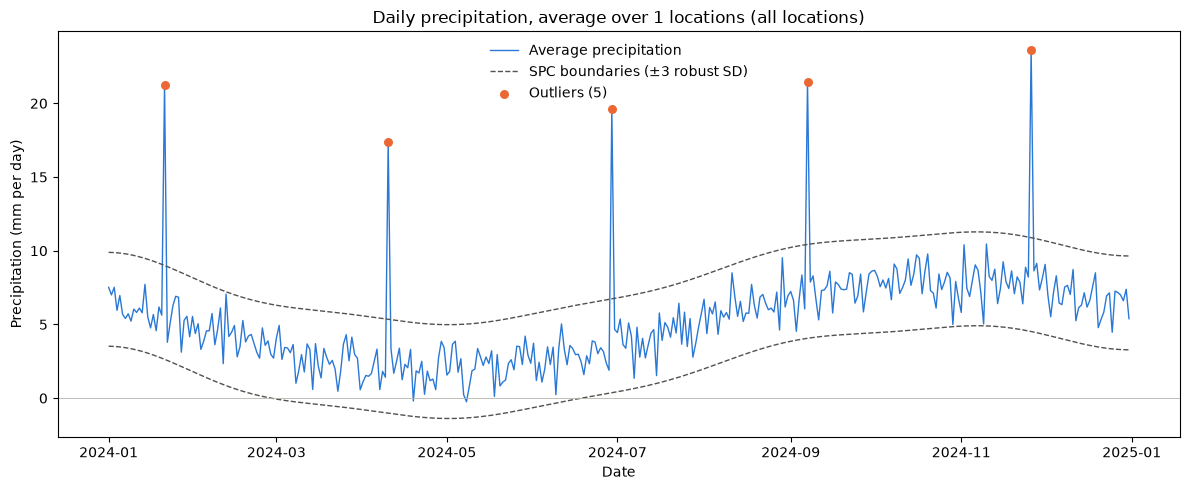

In [15]:
rng = np.random.default_rng(320)
dates = pd.date_range("2024-01-01", "2024-12-31")
season = 5 + 3 * np.cos(2 * np.pi * (dates.dayofyear.to_numpy() - 300) / 366)   # wetter in autumn
test_values = season + rng.normal(0, 1, len(dates))
spike_days = [20, 100, 180, 250, 330]
test_values[spike_days] += 15
test_weather = pd.DataFrame({"date": dates, "precipitation_sum": test_values})

fig, test_outliers, test_summary = precipitation_outliers(test_weather)

# all five spikes found, and few false alarms (about 1 in 370 days is expected at 3 SD)
assert set(dates[spike_days]) <= set(test_outliers.index)
assert test_summary["outliers"] <= len(spike_days) + 3

# more standard deviations -> fewer or equal outliers
counts = [precipitation_outliers(test_weather, n_std=k)[2]["outliers"] for k in [2, 3, 4]]
assert counts[0] >= counts[1] >= counts[2]

# the cutoff must make sense
for bad_cutoff in [0, len(dates)]:
    try:
        precipitation_outliers(test_weather, cutoff=bad_cutoff)
        raise AssertionError("expected an error")
    except ValueError:
        pass

print("All tests passed")
print(test_summary)
fig


### NO 3 (EL 3) in 2024


{'days': 366, 'outliers': 18, 'share_outliers': 0.049, 'above': 18, 'below': 0, 'seasonal_cycles_longer_than_days': 73.2, 'satv_median': -1.1, 'satv_robust_sd': 3.54, 'precipitation_in_outliers_mm': 351.9, 'share_of_total_precipitation': 0.198}


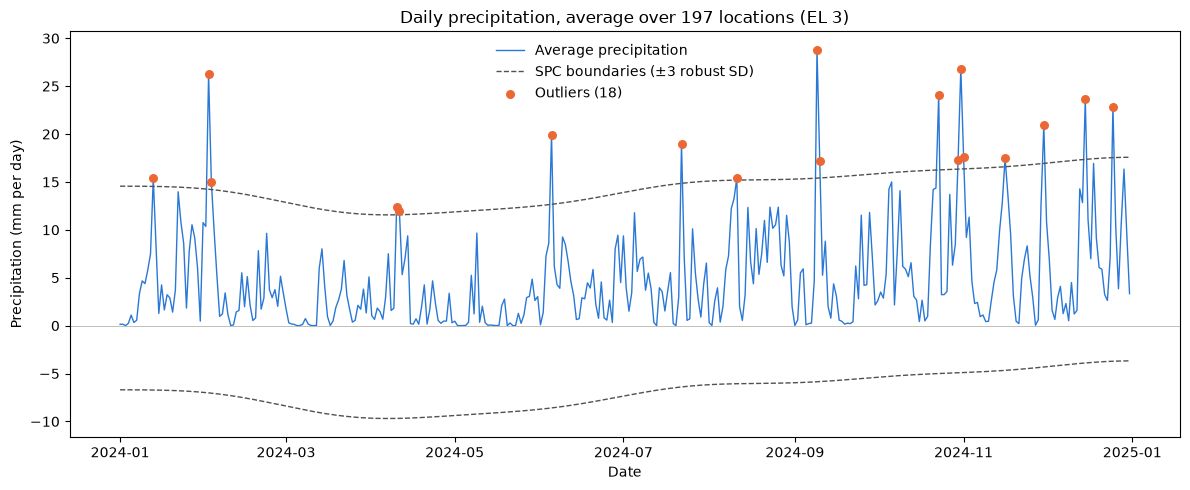

In [16]:
fig, outliers_el3, summary_el3 = precipitation_outliers(weather_el3)
print(summary_el3)
fig


In [17]:
# the outlier days, heaviest first
outliers_el3.sort_values("precipitation", ascending=False)


,precipitation,seasonal,lower,upper,satv,direction
date,,,,,,
2024-09-09,28.80,5.87,-5.86,15.40,22.92,above
2024-10-31,26.83,6.83,-4.91,16.35,20.01,above
2024-02-02,26.23,4.71,-7.02,14.24,21.51,above
2024-10-23,24.09,6.73,-5.00,16.26,17.36,above
2024-12-15,23.62,7.83,-3.90,17.36,15.78,above
2024-12-25,22.87,8.02,-3.72,17.54,14.85,above
2024-11-30,20.91,7.41,-4.32,16.93,13.49,above
2024-06-05,19.89,3.14,-8.59,12.66,16.75,above
2024-07-22,18.98,5.33,-6.40,14.86,13.65,above


In [18]:
# how sensitive is the result to the parameters?
pd.DataFrame(
    [{"cutoff": c, "n_std": k, **precipitation_outliers(weather_el3, cutoff=c, n_std=k)[2]}
     for c in [5, 10, 20, 50] for k in [2, 3]]
)[["cutoff", "n_std", "seasonal_cycles_longer_than_days", "outliers", "above", "below", "satv_robust_sd"]]


,cutoff,n_std,seasonal_cycles_longer_than_days,outliers,above,below,satv_robust_sd
0,5,2,146.4,39,39,0,3.53
1,5,3,146.4,18,18,0,3.53
2,10,2,73.2,38,38,0,3.54
3,10,3,73.2,18,18,0,3.54
4,20,2,36.6,35,35,0,3.54
5,20,3,36.6,12,12,0,3.54
6,50,2,14.6,38,27,11,2.92
7,50,3,14.6,17,14,3,2.92


## Temperature anomalies with Local Outlier Factor

The average temperature over all locations in a region is plotted against time, and anomalies are found with the Local Outlier Factor (LOF) method. LOF compares how densely packed each point is with how densely packed its nearest neighbours are. A point in a much emptier area than its neighbours is an outlier.

Each day is a point with two features: the date and the temperature, both standardised so neither one dominates the distances. The neighbours of a day are then days that are close both in time and in temperature, so a day is flagged when it is very different from the days around it, not just when it is cold or warm for the year. Using only the temperature would flag the warmest summer days and the coldest winter days, which are normal for their season.

`proportion` is the share of days marked as outliers (LOF's `contamination`), 1% by default. `n_neighbors` is the number of neighbours, 20 by default (the scikit-learn default). The first and last days of the period only have neighbours on one side, so they are flagged a little more easily.


In [19]:
from sklearn.neighbors import LocalOutlierFactor

def temperature_anomalies(weather, proportion=0.01, n_neighbors=20, column="temperature_2m_mean"):
    """Find unusual days in the average temperature with the Local Outlier Factor method.

    weather: daily data with a "date" column, for one or more locations
    proportion: share of the days marked as outliers (0 < proportion <= 0.5)
    n_neighbors: number of neighbours LOF compares each day with

    Returns the figure, a table of the outlier days and a summary.
    """
    if not 0 < proportion <= 0.5:
        raise ValueError("proportion must be above 0 and at most 0.5")

    daily = weather.groupby("date")[column].mean().sort_index()
    values = daily.to_numpy()
    days = np.arange(len(values))

    # date and temperature, standardised so both count equally
    features = np.column_stack([
        (days - days.mean()) / days.std(),
        (values - values.mean()) / values.std(),
    ])
    lof = LocalOutlierFactor(n_neighbors=n_neighbors, contamination=proportion)
    is_outlier = lof.fit_predict(features) == -1

    fig, ax = plt.subplots(figsize=(12, 5))
    ax.plot(daily.index, values, color="#2a78d6", linewidth=1, label="Average temperature")
    ax.scatter(daily.index[is_outlier], values[is_outlier], color="#eb6834", s=30, zorder=3,
               label=f"LOF outliers ({is_outlier.sum()})")
    region = ", ".join(weather["region"].unique()) if "region" in weather else "all locations"
    n_locations = weather["point_id"].nunique() if "point_id" in weather else 1
    ax.set_title(f"Daily mean temperature, average over {n_locations} locations ({region})")
    ax.set_xlabel("Date")
    ax.set_ylabel("Temperature (°C)")
    ax.legend(frameon=False)
    plt.tight_layout()
    plt.close(fig)   # show it where the function is called, not twice

    # compare each outlier with the median of the two weeks around it, to say if it was warm or cold
    local_median = daily.rolling(15, center=True, min_periods=1).median()
    outliers = pd.DataFrame({
        "temperature": values,
        "local_median": local_median.to_numpy(),
        "lof_score": -lof.negative_outlier_factor_,   # around 1 is normal, higher is more unusual
    }, index=daily.index)[is_outlier]
    outliers["difference"] = outliers["temperature"] - outliers["local_median"]
    outliers["direction"] = np.where(outliers["difference"] > 0, "warmer", "colder")

    summary = {
        "days": len(values),
        "outliers": int(is_outlier.sum()),
        "share_outliers": round(float(is_outlier.mean()), 3),
        "warmer": int((outliers["direction"] == "warmer").sum()),
        "colder": int((outliers["direction"] == "colder").sum()),
        "largest_difference_c": round(float(outliers["difference"].abs().max()), 1) if len(outliers) else None,
        "lof_threshold": round(float(-lof.offset_), 2),
    }
    return fig, outliers.round(2), summary


### Testing the function

Synthetic data with a known answer: a seasonal temperature curve with noise, plus three days that are 12 °C warmer or colder than the days around them. The function should find those three days.


All tests passed
{'days': 366, 'outliers': 4, 'share_outliers': 0.011, 'warmer': 2, 'colder': 2, 'largest_difference_c': 13.2, 'lof_threshold': 1.56}


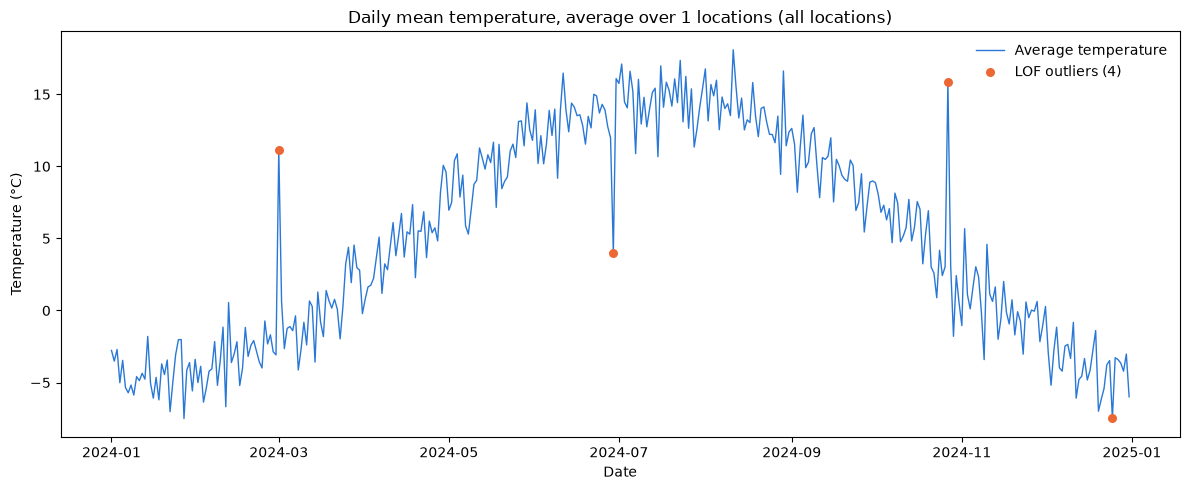

In [20]:
rng = np.random.default_rng(320)
dates = pd.date_range("2024-01-01", "2024-12-31")
season = 5 - 10 * np.cos(2 * np.pi * (dates.dayofyear.to_numpy() - 15) / 366)   # cold in January
test_values = season + rng.normal(0, 1.5, len(dates))
anomaly_days = [60, 180, 300]
test_values[anomaly_days] += [12, -12, 12]
test_weather = pd.DataFrame({"date": dates, "temperature_2m_mean": test_values})

fig, test_outliers, test_summary = temperature_anomalies(test_weather)

# the three planted anomalies are found
assert set(dates[anomaly_days]) <= set(test_outliers.index)
assert list(test_outliers.loc[dates[anomaly_days], "direction"]) == ["warmer", "colder", "warmer"]

# the proportion decides how many days are marked
for proportion in [0.01, 0.05, 0.1]:
    marked = temperature_anomalies(test_weather, proportion=proportion)[2]["outliers"]
    assert abs(marked - proportion * len(dates)) <= 1, (proportion, marked)

# a proportion outside (0, 0.5] is refused
for bad_proportion in [0, 0.6]:
    try:
        temperature_anomalies(test_weather, proportion=bad_proportion)
        raise AssertionError("expected an error")
    except ValueError:
        pass

print("All tests passed")
print(test_summary)
fig


### NO 3 (EL 3) in 2024


{'days': 366, 'outliers': 4, 'share_outliers': 0.011, 'warmer': 1, 'colder': 3, 'largest_difference_c': 6.7, 'lof_threshold': 1.61}


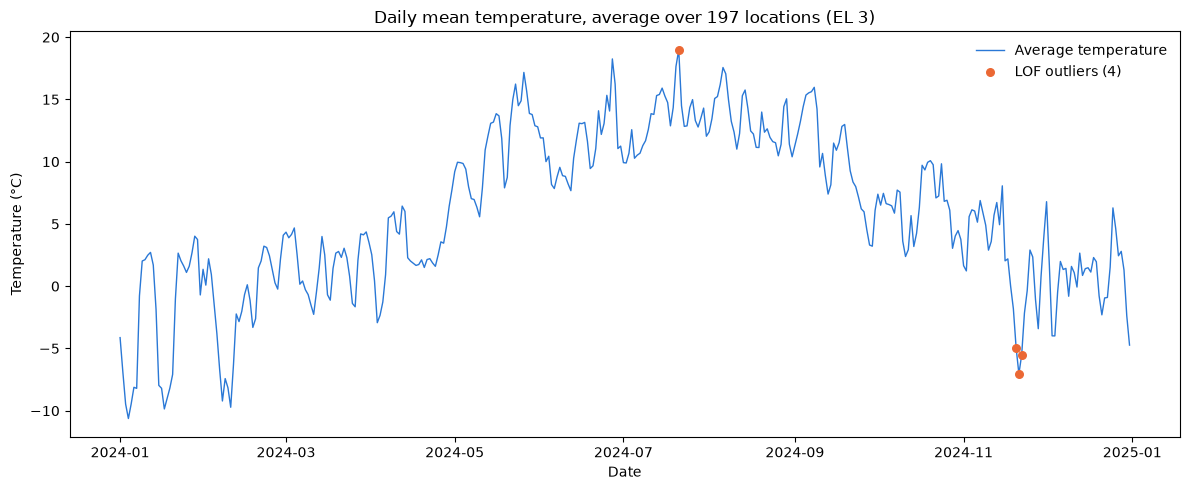

In [21]:
fig, anomalies_el3, anomaly_summary_el3 = temperature_anomalies(weather_el3)
print(anomaly_summary_el3)
fig


In [22]:
anomalies_el3


,temperature,local_median,lof_score,difference,direction
date,,,,,
2024-07-21,18.99,14.49,1.75,4.49,warmer
2024-11-20,-4.96,0.01,1.62,-4.97,colder
2024-11-21,-7.05,-0.36,2.06,-6.68,colder
2024-11-22,-5.52,-0.36,1.72,-5.16,colder


{'days': 366, 'outliers': 19, 'share_outliers': 0.052, 'warmer': 9, 'colder': 10, 'largest_difference_c': 6.7, 'lof_threshold': 1.25}


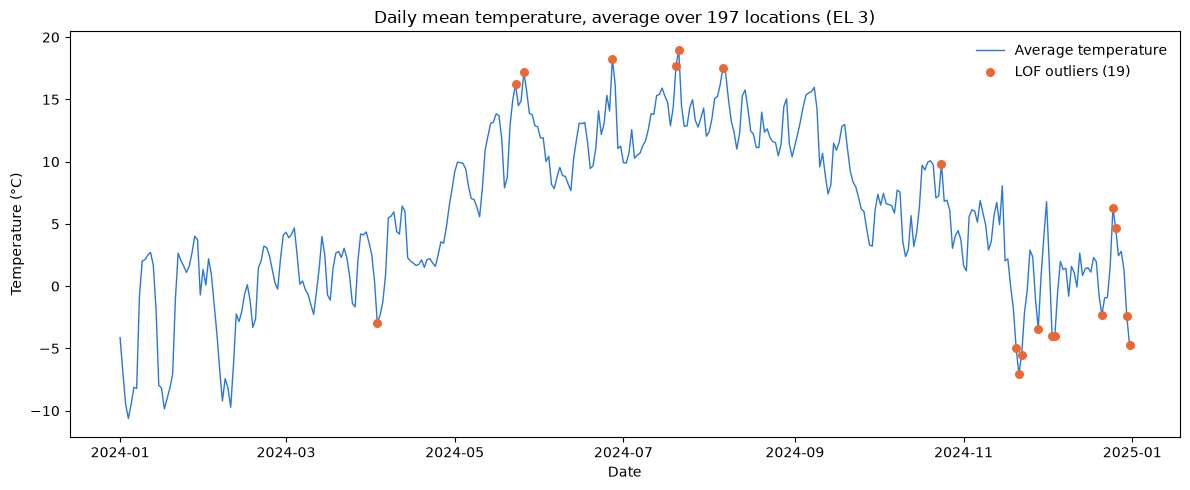

In [23]:
# with 5% outliers, to see which kind of days LOF picks next
fig, anomalies_el3_5, summary_5 = temperature_anomalies(weather_el3, proportion=0.05)
print(summary_5)
fig


## Seasonal-Trend decomposition with LOESS (STL)

STL splits the weekly degree of filling from Magasinstatistikk into three parts: observed = trend + seasonal + residual. LOESS (local regression) is used to smooth out each part. The data is weekly, so one year is `period=52`.

The parameters and their defaults:

- `seasonal=13`: the length of the seasonal smoother, counted in years for each week of the year. With 13, the yearly pattern can change slowly over about a decade, for example if reservoirs are run differently now than in the 1990s. It must be odd and at least 7.
- `trend=105`: the length of the trend smoother in weeks, about two years. That is long enough not to follow the yearly cycle, and short enough to show dry and wet years. It must be odd and longer than the period.
- `robust=True`: gives less weight to unusual weeks, so very dry or wet years do not bend the trend and the seasonal pattern.

Some ISO years have 53 weeks, so a fixed period of 52 drifts by one week every few years. The seasonal smoother absorbs this.


In [24]:
from statsmodels.tsa.seasonal import STL

def stl_fill_ratio(reservoirs, area="EL 3", seasonal=13, trend=105, robust=True, period=52):
    """STL decomposition of the weekly degree of filling for one area, e.g. "NO 0", "EL 3" or "VASS 1".

    reservoirs: the Magasinstatistikk data as it comes from the API (dato_Id, omrType, omrnr, fyllingsgrad)
    seasonal: length of the seasonal smoother (odd, at least 7)
    trend: length of the trend smoother in weeks (odd, longer than the period)
    robust: give less weight to unusual weeks

    Returns the figure with the observed series, trend, seasonal part and residual.
    """
    if seasonal < 7 or seasonal % 2 == 0:
        raise ValueError("seasonal must be odd and at least 7")
    if trend <= period or trend % 2 == 0:
        raise ValueError(f"trend must be odd and longer than the period ({period})")

    area_type, area_number = area.split()
    rows = reservoirs[(reservoirs["omrType"] == area_type) & (reservoirs["omrnr"] == int(area_number))]
    if rows.empty:
        raise ValueError(f"No data for area {area}")
    fill = rows.set_index(pd.to_datetime(rows["dato_Id"]))["fyllingsgrad"].sort_index()

    result = STL(fill, period=period, seasonal=seasonal, trend=trend, robust=robust).fit()

    parts = [
        ("Observed", result.observed),
        ("Trend", result.trend),
        ("Seasonal", result.seasonal),
        ("Residual", result.resid),
    ]
    fig, axes = plt.subplots(4, 1, figsize=(12, 9), sharex=True)
    for ax, (name, values) in zip(axes, parts):
        ax.plot(fill.index, values, color="#2a78d6", linewidth=0.8)
        ax.set_ylabel(name)
    for ax in axes[2:]:
        ax.axhline(0, color="#b5b4ad", linewidth=0.6)   # seasonal and residual vary around 0
    axes[-1].set_xlabel("Date")
    fig.suptitle(f"STL of the degree of filling for {area} "
                 f"(seasonal={seasonal}, trend={trend}, robust={robust})")
    plt.tight_layout()
    plt.close(fig)   # show it where the function is called, not twice
    return fig


### Testing the function

Synthetic data with a known answer: 20 years of weekly values made of a slowly rising trend, a yearly cosine with an amplitude of 0.3, noise, and five weeks with large errors. The function should recover the trend and the seasonal amplitude, and `robust=True` should keep the trend closer to the true one despite the errors. The components are read back from the figure, so the test also checks what is plotted.


All tests passed
Mean trend error: robust 0.0009, not robust 0.0028


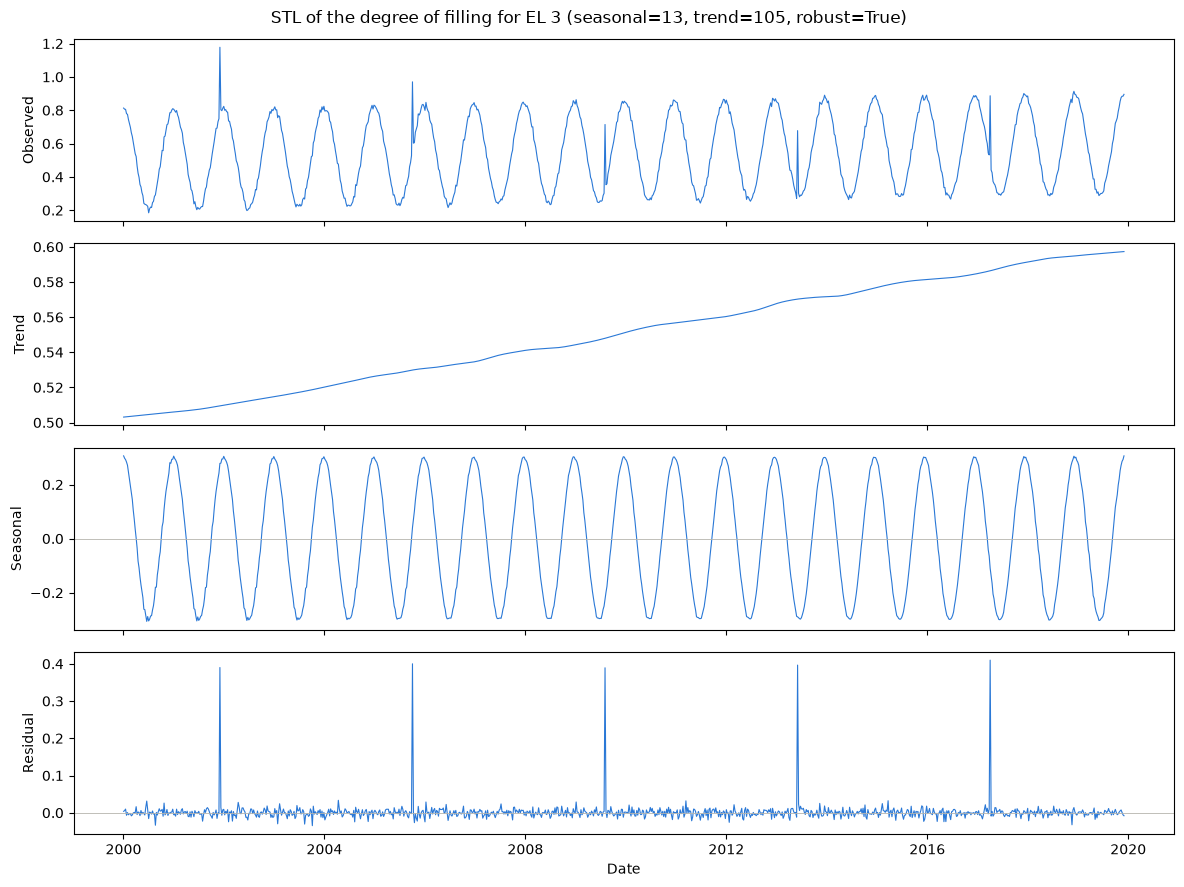

In [25]:
def components(fig):
    """Observed, trend, seasonal and residual values from the four panels."""
    return [ax.lines[0].get_ydata() for ax in fig.axes]

rng = np.random.default_rng(320)
weeks = np.arange(20 * 52)
true_trend = 0.5 + 0.1 * weeks / len(weeks)
true_seasonal = 0.3 * np.cos(2 * np.pi * weeks / 52)
test_fill = true_trend + true_seasonal + rng.normal(0, 0.01, len(weeks))
test_fill[[100, 300, 500, 700, 900]] += 0.4   # weeks with large errors

test_reservoirs = pd.DataFrame({
    "dato_Id": pd.date_range("2000-01-02", periods=len(weeks), freq="7D").strftime("%Y-%m-%d"),
    "omrType": "EL",
    "omrnr": 3,
    "fyllingsgrad": test_fill,
})

fig = stl_fill_ratio(test_reservoirs)
observed, trend_part, seasonal_part, residual = components(fig)

# the parts add up to the data
assert np.allclose(observed, trend_part + seasonal_part + residual)
# the seasonal amplitude (0.3, so 0.6 from top to bottom) and the trend are recovered
assert abs((seasonal_part.max() - seasonal_part.min()) - 0.6) < 0.05
assert np.abs(trend_part - true_trend).max() < 0.02

# robust=True is less disturbed by the error weeks than robust=False
robust_error = np.abs(components(stl_fill_ratio(test_reservoirs, robust=True))[1] - true_trend).mean()
plain_error = np.abs(components(stl_fill_ratio(test_reservoirs, robust=False))[1] - true_trend).mean()
assert robust_error < plain_error

# invalid parameters and unknown areas are refused
for bad in [dict(seasonal=8), dict(seasonal=5), dict(trend=51), dict(trend=104), dict(area="EL 9")]:
    try:
        stl_fill_ratio(test_reservoirs, **bad)
        raise AssertionError(f"expected an error for {bad}")
    except ValueError:
        pass

print("All tests passed")
print(f"Mean trend error: robust {robust_error:.4f}, not robust {plain_error:.4f}")
fig


### NO 3 (EL 3), 1995–2026


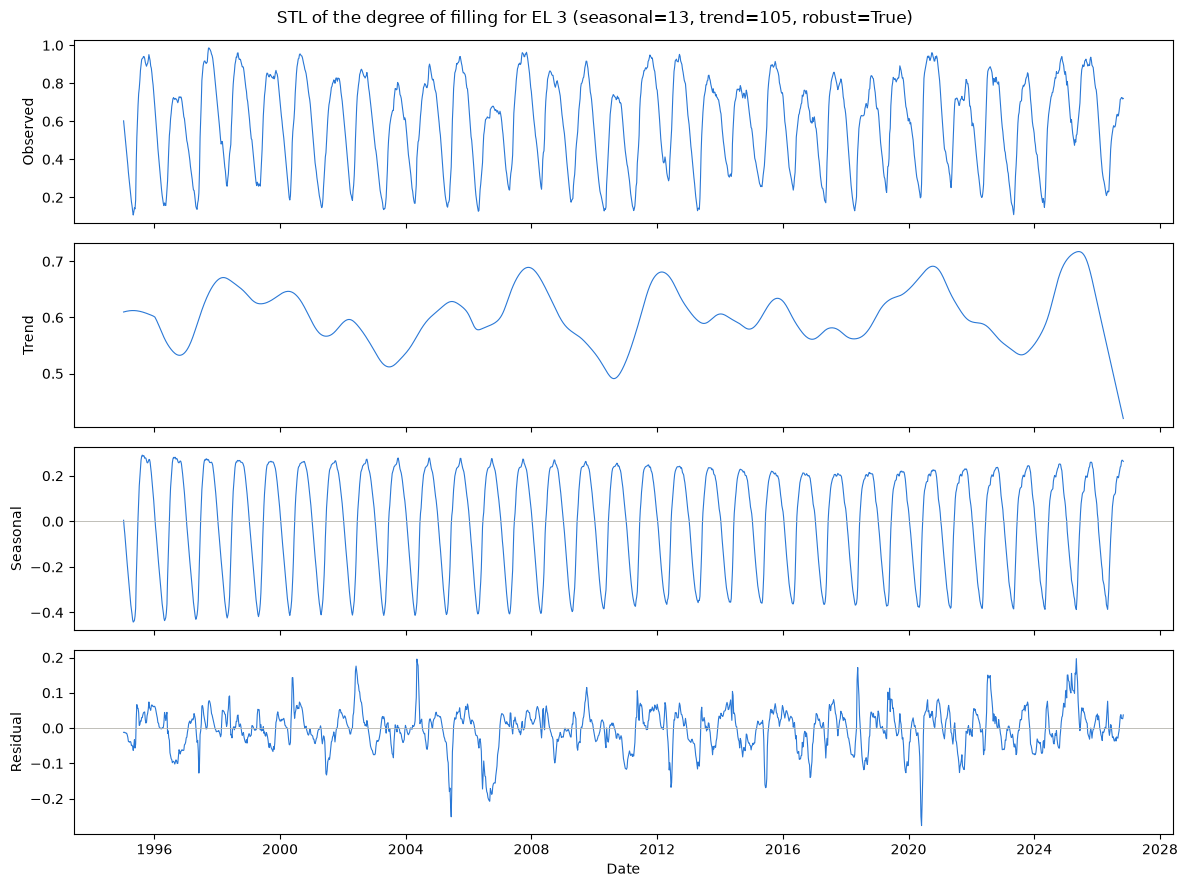

In [26]:
stl_fill_ratio(reservoirs, area="EL 3")


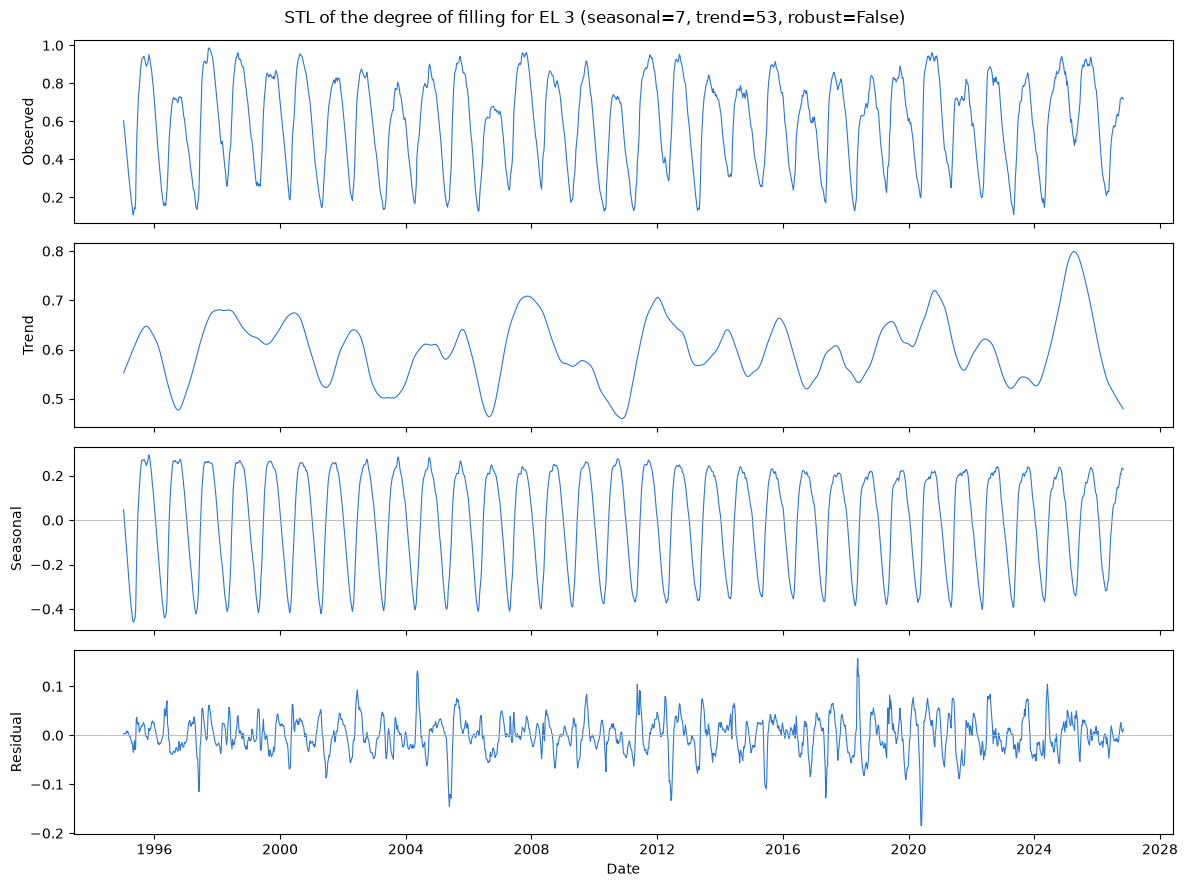

In [27]:
# a shorter seasonal smoother lets the yearly pattern change faster
stl_fill_ratio(reservoirs, area="EL 3", seasonal=7, trend=53, robust=False)


## Spectrogram

The spectrogram uses the same weekly degree of filling as the STL. The series is cut into overlapping windows, and the frequency content of each window is computed (`scipy.signal.spectrogram`). This shows how strong each cycle is, and whether that changes over time. With weekly data and `fs=52`, frequencies are in cycles per year, so the yearly filling and emptying of the reservoirs is at 1.

The parameters and their defaults:

- `window=156` weeks (3 years): the frequency resolution is `1 / window length in years`, here 1/3 cycle per year. That separates the yearly cycle (1) from the half-yearly (2), and still gives many windows over 30 years.
- `overlap=130` weeks: each window moves 26 weeks (half a year) from the previous one, so the time axis is smooth.

The power is shown in decibels (dB) because the yearly cycle is much stronger than everything else. The plot shows up to 6 cycles per year, where almost all the power is; the full range goes up to 26 (half the sampling rate).


In [28]:
from scipy.signal import spectrogram

def spectrogram_fill_ratio(reservoirs, area="EL 3", window=156, overlap=130, max_frequency=6):
    """Spectrogram of the weekly degree of filling for one area, e.g. "NO 0", "EL 3" or "VASS 1".

    reservoirs: the Magasinstatistikk data as it comes from the API (dato_Id, omrType, omrnr, fyllingsgrad)
    window: window length in weeks
    overlap: how many weeks each window shares with the next one (less than window)
    max_frequency: highest frequency shown, in cycles per year

    Returns the figure.
    """
    area_type, area_number = area.split()
    rows = reservoirs[(reservoirs["omrType"] == area_type) & (reservoirs["omrnr"] == int(area_number))]
    if rows.empty:
        raise ValueError(f"No data for area {area}")
    fill = rows.set_index(pd.to_datetime(rows["dato_Id"]))["fyllingsgrad"].sort_index()

    if not 2 <= window <= len(fill):
        raise ValueError(f"window must be between 2 and {len(fill)} weeks")
    if not 0 <= overlap < window:
        raise ValueError("overlap must be at least 0 and less than window")

    # 52 samples per year, so the frequencies come out in cycles per year
    frequencies, times, power = spectrogram(fill.to_numpy(), fs=52, nperseg=window, noverlap=overlap)
    power_db = 10 * np.log10(power + 1e-12)   # avoid log(0)
    window_centres = fill.index[0] + pd.to_timedelta(times * 52 * 7, unit="D")   # years -> dates

    fig, ax = plt.subplots(figsize=(12, 5))
    # colour the top 50 dB; a few almost empty cells would otherwise stretch the scale
    mesh = ax.pcolormesh(window_centres, frequencies, power_db, shading="nearest", cmap="Blues",
                         vmin=power_db.max() - 50, vmax=power_db.max())
    fig.colorbar(mesh, ax=ax, label="Power (dB)")
    ax.set_ylim(0, max_frequency)
    ax.set_xlabel("Date (centre of the window)")
    ax.set_ylabel("Frequency (cycles per year)")
    ax.set_title(f"Spectrogram of the degree of filling for {area} "
                 f"(window {window} weeks, overlap {overlap} weeks)")
    plt.tight_layout()
    plt.close(fig)   # show it where the function is called, not twice
    return fig


### Testing the function

Synthetic data with a known answer: 30 years of weekly values with a cycle of 1 per year in the first half and 2 per year in the second half. The strongest frequency in the spectrogram should move from 1 to 2. The values are read back from the figure. The test also checks that the window and overlap give the expected number of windows and frequency resolution.


All tests passed


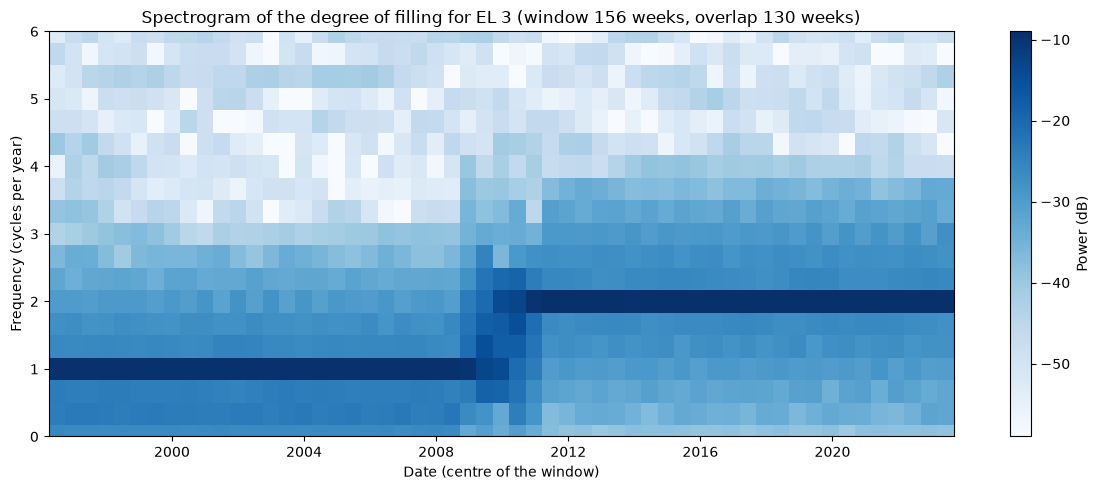

In [29]:
def spectrogram_values(fig):
    """Power (frequencies × windows) from the plotted spectrogram, in dB."""
    return np.asarray(fig.axes[0].collections[0].get_array())

n_weeks = 30 * 52
weeks = np.arange(n_weeks)
test_signal = np.where(weeks < n_weeks // 2,
                       np.cos(2 * np.pi * weeks / 52),        # 1 cycle per year
                       np.cos(2 * np.pi * 2 * weeks / 52))    # 2 cycles per year
rng = np.random.default_rng(320)
test_reservoirs = pd.DataFrame({
    "dato_Id": pd.date_range("1995-01-08", periods=n_weeks, freq="7D").strftime("%Y-%m-%d"),
    "omrType": "EL",
    "omrnr": 3,
    "fyllingsgrad": 0.5 + 0.3 * test_signal + rng.normal(0, 0.02, n_weeks),
})

window, overlap = 156, 130
fig = spectrogram_fill_ratio(test_reservoirs, window=window, overlap=overlap)
power = spectrogram_values(fig)
frequencies = np.fft.rfftfreq(window, d=1 / 52)

# the expected shape: frequencies from 0 to 26, and one column per step of window - overlap weeks
assert power.shape == (len(frequencies), (n_weeks - overlap) // (window - overlap))

# the strongest frequency moves from 1 to 2 cycles per year
peaks = frequencies[power.argmax(axis=0)]
assert np.allclose(peaks[:20], 1) and np.allclose(peaks[-20:], 2)

# a longer window gives a finer frequency resolution and fewer windows
long_power = spectrogram_values(spectrogram_fill_ratio(test_reservoirs, window=260, overlap=208))
assert long_power.shape[0] > power.shape[0] and long_power.shape[1] < power.shape[1]

# invalid parameters are refused
for bad in [dict(window=1), dict(window=n_weeks + 1), dict(overlap=156), dict(overlap=-1)]:
    try:
        spectrogram_fill_ratio(test_reservoirs, **bad)
        raise AssertionError(f"expected an error for {bad}")
    except ValueError:
        pass

print("All tests passed")
fig


### NO 3 (EL 3), 1995–2026


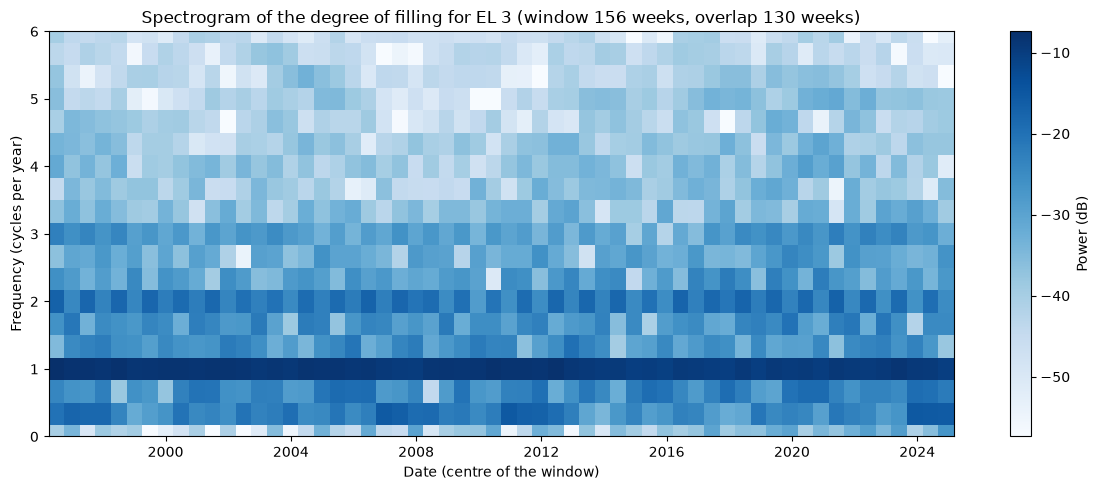

In [30]:
spectrogram_fill_ratio(reservoirs, area="EL 3")


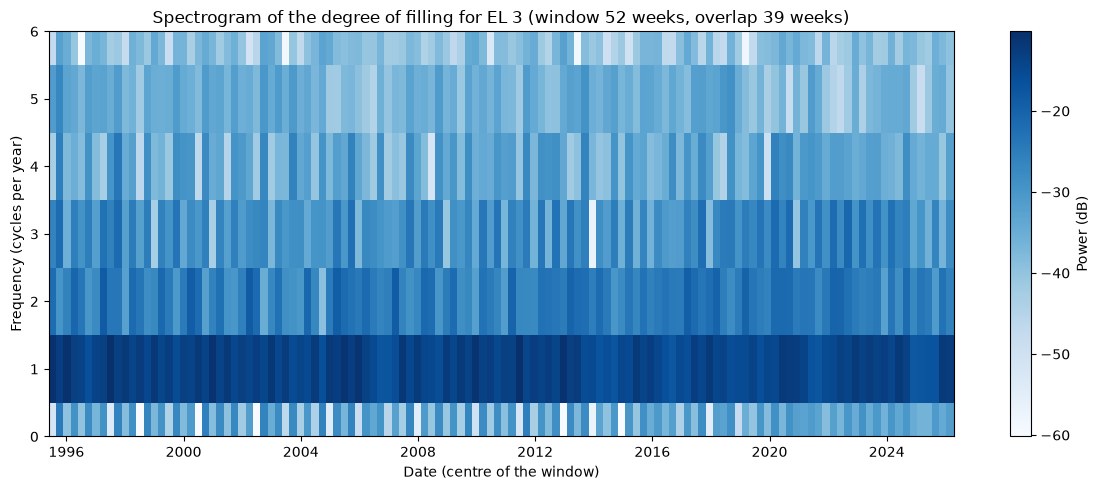

In [31]:
# a one-year window: finer in time, but frequencies only every 1 cycle per year
spectrogram_fill_ratio(reservoirs, area="EL 3", window=52, overlap=39)


## Log


i started we downloading the shapefilse from NVE atalts. thise represented the electricity areas and precipitation areas that correspond to the Magasinstatistikk data used earlier in the project. since we only have vass 1, 2, and 3 i needed to combine some of the regions. Then i verefyed thet the areas mach up withe the power capacity for whole norway.

## AI usage
